## Exploratory Data Analysis for Finance

German Credit Risk Dataset - a classroom demo

### Load Packages

In this section, we import the libraries we need for our project. Pandas is used to read and organize the data, and NumPy helps with calculations. Matplotlib and Seaborn are used to make charts and understand the data. We also import tools to convert text values into numbers, scale numerical data, and select useful features. These libraries help us prepare and analyze the data.

In [ ]:
%matplotlib inline

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.feature_selection import SelectKBest, f_classif

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 20)

print("All packages loaded successfully.")


All packages loaded successfully.


### Load the Dataset

In this section, we load the CSV file using Pandas and save the data in a DataFrame called `dataset`. We use `DATA_PATH` to store the file name, and `pd.read_csv()` to read the file. Finally, we check the number of rows and columns to make sure the dataset loaded correctly. The dataset contains 1,000 rows and 10 columns.

In [ ]:
DATA_PATH = "german_credit_data.csv"

dataset = pd.read_csv(DATA_PATH)

print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns")


Dataset loaded: 1000 rows, 10 columns


### A First Look at the Records

In this section, we use `head()` to see the first five rows of the dataset. This helps us understand how the data looks and check the column names and some values. We can see information like age, sex, credit amount, loan duration, and risk. We can also notice that some values are missing. This step gives us a first idea about the data before analyzing it.

In [ ]:
dataset.head()


,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


### Checking the table size

In this section, we use `shape` to check the size of the dataset. The result shows that the dataset has 1,000 rows and 10 columns. This helps us make sure that the data was loaded correctly.

In [ ]:
print("Shape (rows, columns):", dataset.shape)


Shape (rows, columns): (1000, 10)


### Recognizing variable formats

In this section, we use `dtypes` to check the data type of each column. Some columns contain numbers, like Age and CreditAmount, while others contain text, like Gender and Risk. Knowing the data types helps us understand how to work with each column during the analysis.

In [ ]:
dataset.dtypes


,0
Age,int64
Sex,object
Job,int64
Housing,object
SavingAccounts,object
CheckingAccount,object
CreditAmount,int64
Duration,int64
Purpose,object
Risk,object


### Summarizing numerical characteristics

In this section, we use `describe()` to get a summary of the numerical columns. It shows the average, minimum, maximum, and other statistics. For example, the mean credit amount is about 3,271, while the median is 2,319.5. This helps us understand the data and how the values are spread.

In [ ]:
dataset.describe()


,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


### Reading the categorical summary

In this section, we use `describe(exclude="number")` to summarize the categorical columns. It shows the number of values, the number of different categories, and the most common category. This helps us understand columns like Sex, Housing, Purpose, and Risk. We can also notice that some columns have missing values.

In [ ]:
dataset.describe(exclude="number")


,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


### Locating gaps in the data

In this section, we use `isna().sum()` to find missing values in each column. We can see that `SavingAccounts` has 183 missing values and `CheckingAccount` has 394. The other columns have no missing values. This helps us know which columns need cleaning before continuing the analysis.

In [ ]:
missing_counts = dataset.isna().sum()
print("Missing values per column:\n")
print(missing_counts)


Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64


## Part B · Distributions and visual exploration

### Reviewing the target distribution

In this section, we use `value_counts()` to count the values in the `Risk` column. We also calculate the percentage of each category. The results show that 70% of the customers have good credit risk and 30% have bad credit risk. This helps us understand the distribution of the target variable.

In [ ]:
print(dataset["Risk"].value_counts())
print()
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total")


Risk
good    700
bad     300
Name: count, dtype: int64

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


### Visual Comparison of Missing Records

In this section, we use a bar chart to compare the missing values in different columns. The chart shows that `CheckingAccount` has more missing values than `SavingAccounts`. This makes it easier to see which columns need more attention during data cleaning. The chart only shows the missing values without changing or filling them.

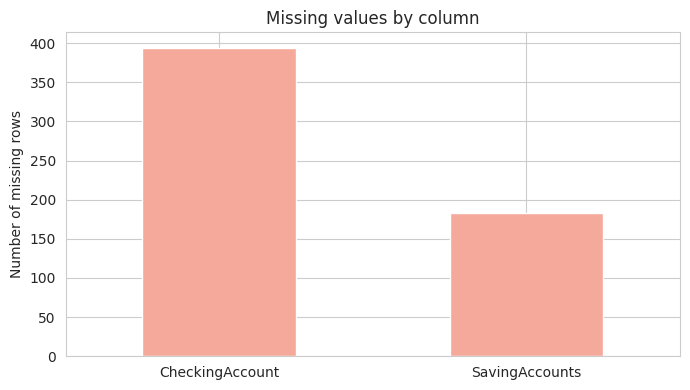

In [ ]:
missing_counts = dataset.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))
missing_counts.plot(kind="bar", color="#f5a99a")
plt.title("Missing values by column")
plt.ylabel("Number of missing rows")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Examining Numeric Frequencies

In this section, we use histograms to understand the distribution of numerical data. We create charts for Age, Job, CreditAmount, and Duration. The charts help us see which values appear more often and how the data is spread. We can notice that most customers are between 20 and 40 years old, and the credit amounts are mostly lower, with some higher values. The Job column contains numbers that represent job categories.

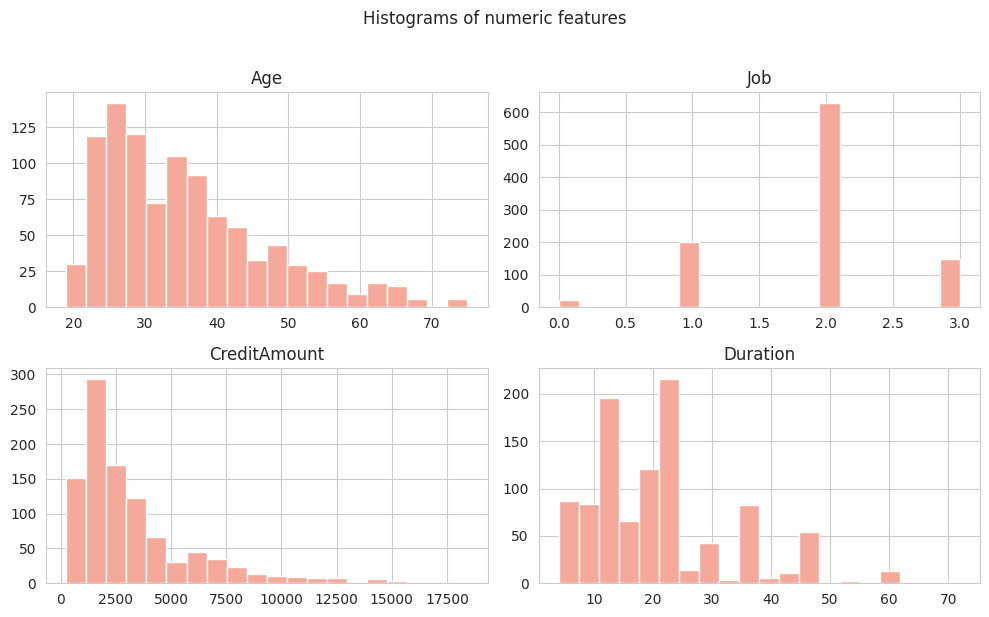

In [ ]:
numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

dataset[numeric_cols].hist(figsize=(10, 6), bins=20, color="#f5a99a", edgecolor="white")
plt.suptitle("Histograms of numeric features", y=1.02)
plt.tight_layout()
plt.show()


### Looking for Unusual Numerical Values

In this section, we use boxplots to find unusual values in the numerical columns. The charts show the median and the spread of the data. We can see some unusual values in Age, CreditAmount, and Duration, especially in CreditAmount. These values may be outliers, but they are not always mistakes. We need to understand them before deciding what to do with them.

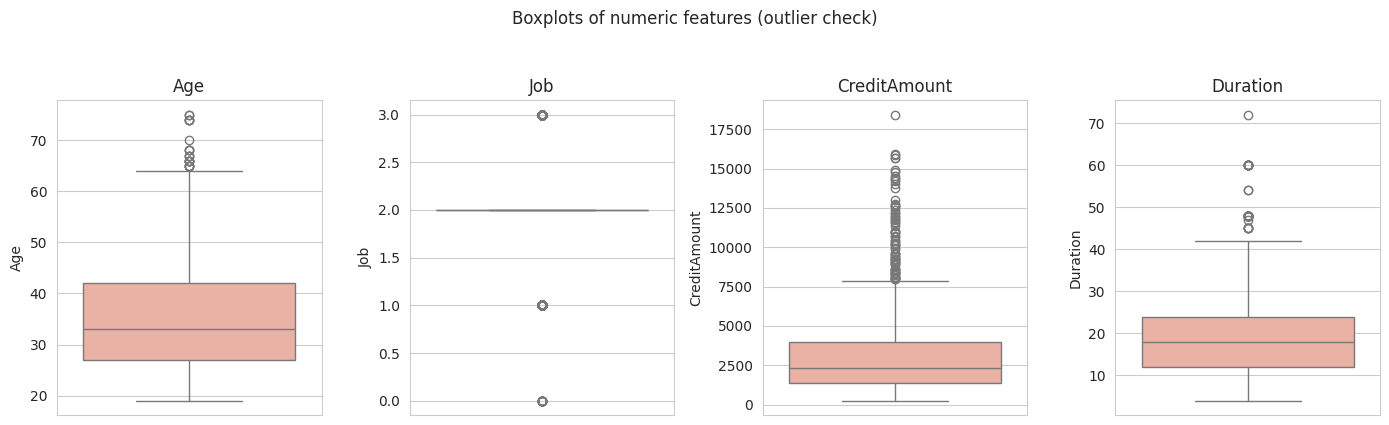

In [ ]:
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=dataset[col], ax=ax, color="#f5a99a")
    ax.set_title(col)
plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05)
plt.tight_layout()
plt.show()


### Counting the Categories

In this section, we use bar charts to count the values in different columns. The charts help us see which categories appear more often. Missing values are shown as "Missing" so we can see them too.

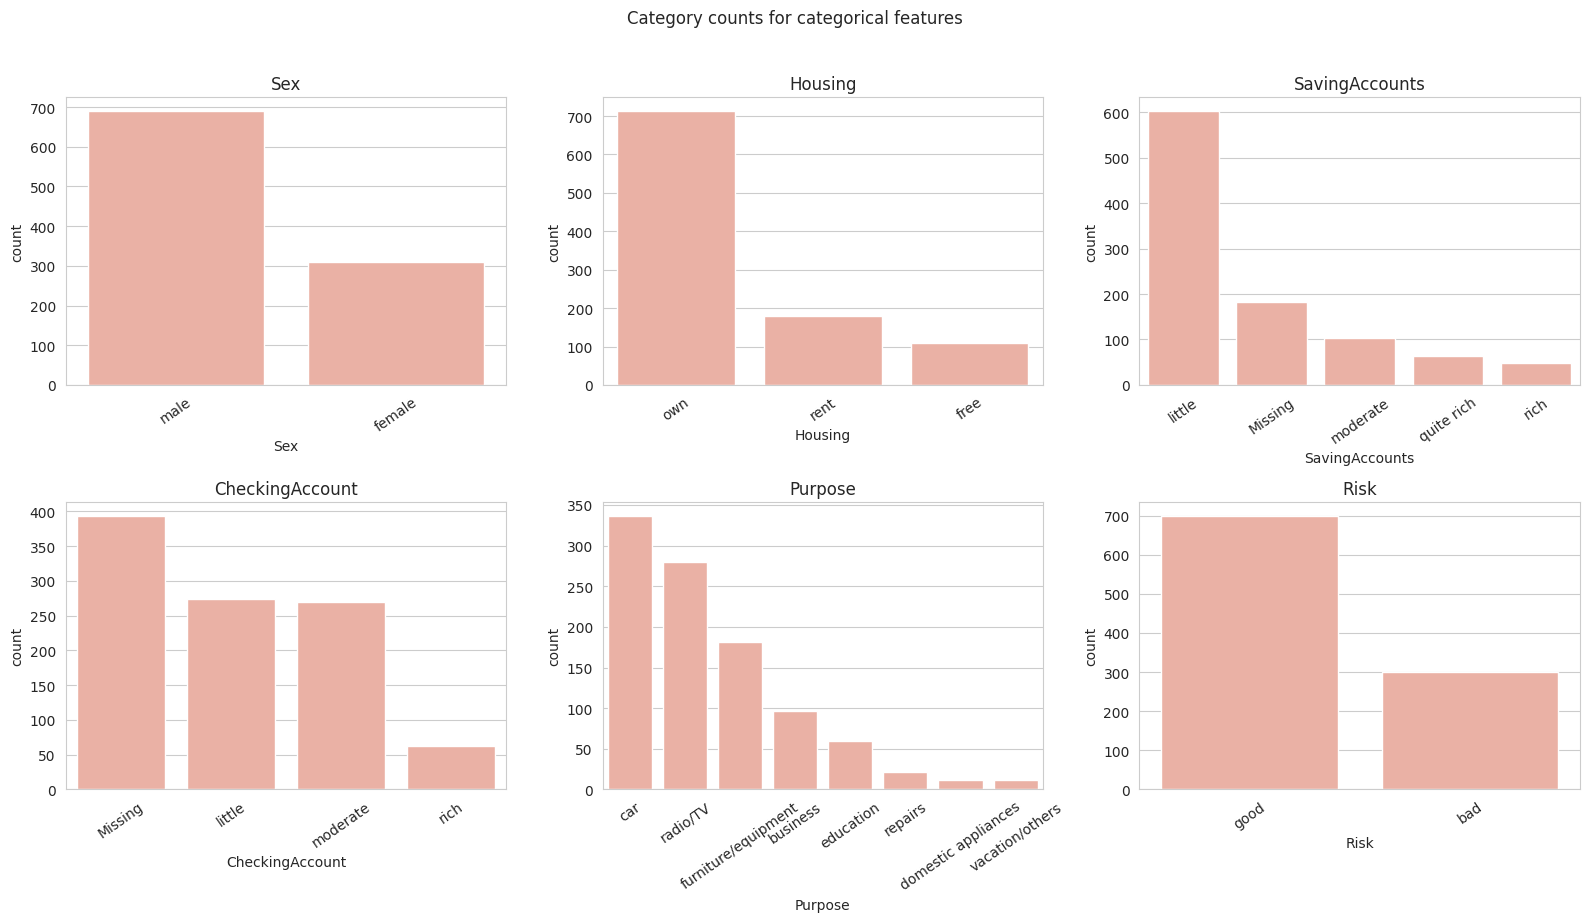

In [ ]:
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, col in zip(axes, categorical_cols):

    col_data = dataset[col].fillna("Missing")

    order = col_data.value_counts().index
    sns.countplot(x=col_data, order=order, ax=ax, color="#f5a99a")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=35)
plt.suptitle("Category counts for categorical features", y=1.02)
plt.tight_layout()
plt.show()


### Exploring Numeric Relationships

In this section, we use a heatmap to show the relationship between numerical columns. The results show that CreditAmount and Duration have a positive relationship, which means that higher credit amounts are usually linked to longer loan durations.

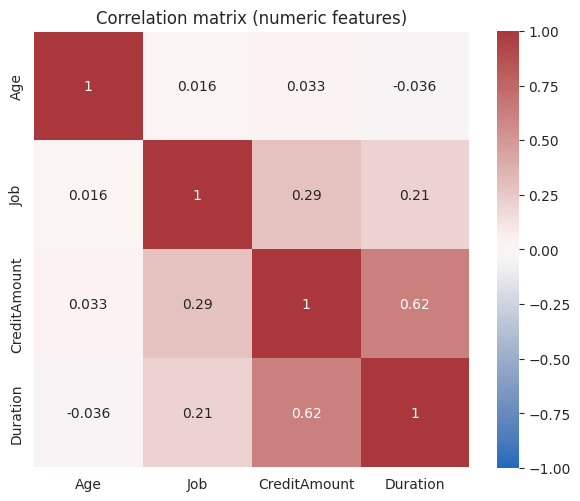

In [ ]:
plt.figure(figsize=(6, 5))
correlation = dataset[numeric_cols].corr()
sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)
plt.title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()


### Comparing Two Features at a Time

In this section, we use a pairplot to compare numerical features and show the good and bad risk groups in different colors. The charts help us see the relationships between the features and whether the two groups have different patterns.

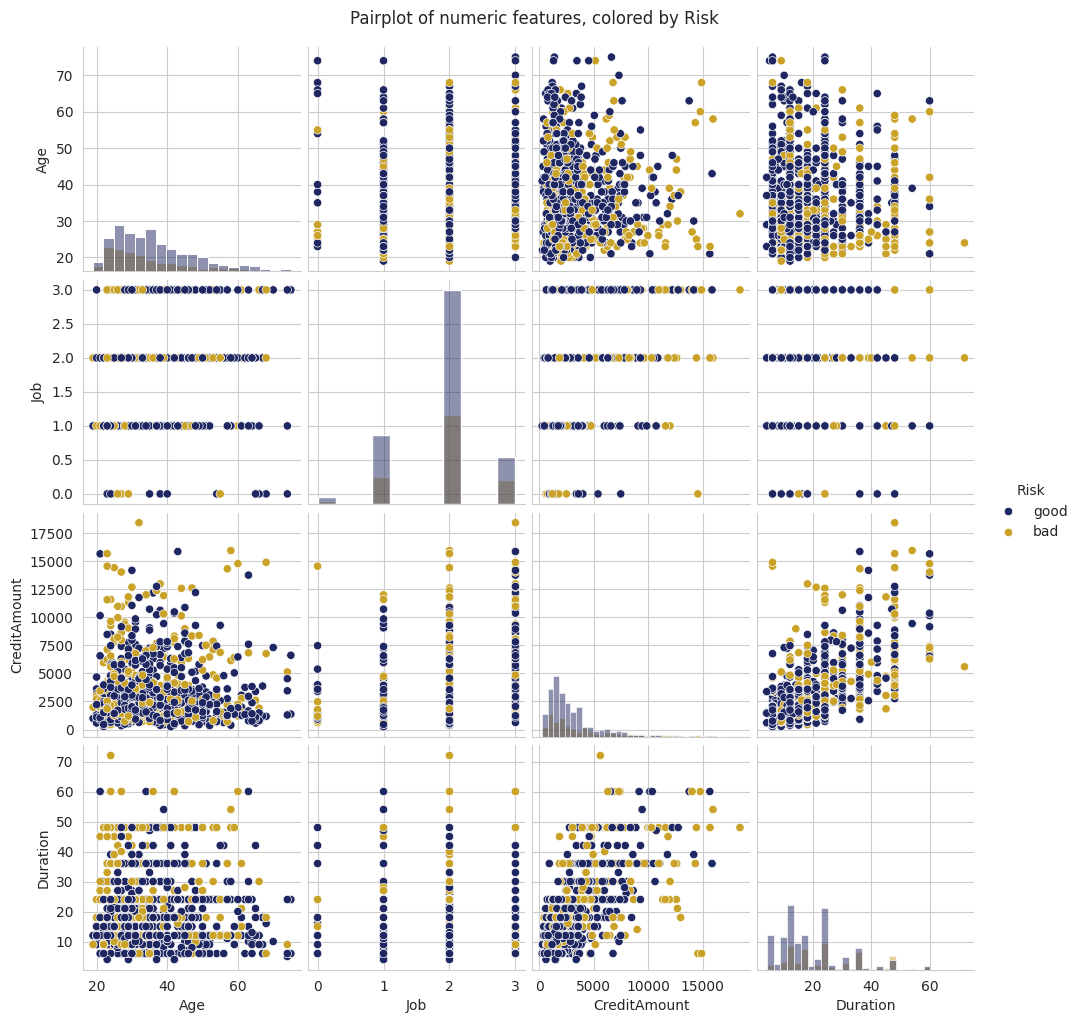

In [ ]:
sns.pairplot(dataset, vars=numeric_cols, hue="Risk", palette={"good": "#1E2761", "bad": "#C9A227"}, diag_kind="hist")
plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)
plt.show()


### Comparing Numeric Patterns Across Risk Labels

In this section, we use boxplots to compare numerical features between good and bad risk groups. The charts help us compare Age, Job, CreditAmount, and Duration. We can see some differences between the two groups, especially in CreditAmount and Duration.

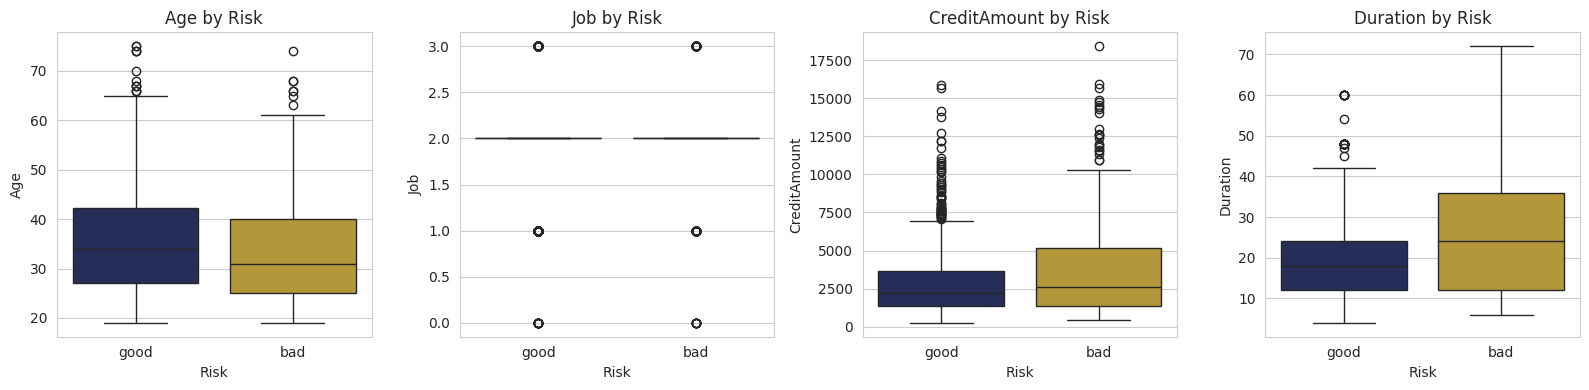

In [ ]:
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=dataset, x="Risk", y=col, hue="Risk",
                palette={"good": "#1E2761", "bad": "#C9A227"}, legend=False, ax=ax)
    ax.set_title(f"{col} by Risk")
plt.tight_layout()
plt.show()


## Part C · Preparing the dataset

### Addressing Missing Account Information

In this section, we make a copy of the dataset and fill the missing values in `SavingAccounts` and `CheckingAccount` with "none". This helps us keep all the rows without missing values in these columns. Finally, we check the data again and see that there are no missing values left.

In [ ]:
df_clean = dataset.copy()

df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")

print("Remaining missing values:\n")
print(df_clean.isna().sum())


Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


### Representing Text Categories Numerically

In this section, we use `LabelEncoder` to change text values into numbers. We apply it to columns like Sex, Housing, Purpose, and Risk. This makes the data easier to use in machine learning. We also print the original categories to see how they were converted.

In [ ]:
df_encoded = df_clean.copy()
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

encoders = {}
for col in categorical_cols_all:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_clean[col])
    encoders[col] = le
    print(f"{col:16s} -> {list(le.classes_)}")


Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'none', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


### Putting Numeric Features on a Comparable Scale

In this section, we use `StandardScaler` to put numerical values on a similar scale. We apply it to Age, Job, CreditAmount, and Duration. The code shows the values before and after scaling so we can see the difference. This helps make the numerical features easier to compare.

In [ ]:
scaler = StandardScaler()
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]

df_scaled = df_encoded.copy()
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale])

print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))
print("\nAfter scaling (mean ~0, std ~1):")
print(df_scaled[numeric_cols_to_scale].head(3).round(3))


Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling (mean ~0, std ~1):
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


### Checking What Scaling Changed

In this section, we compare CreditAmount before and after scaling using histograms. The values change to a different scale, but the data pattern stays the same. Scaling does not remove outliers or fix skewed data.

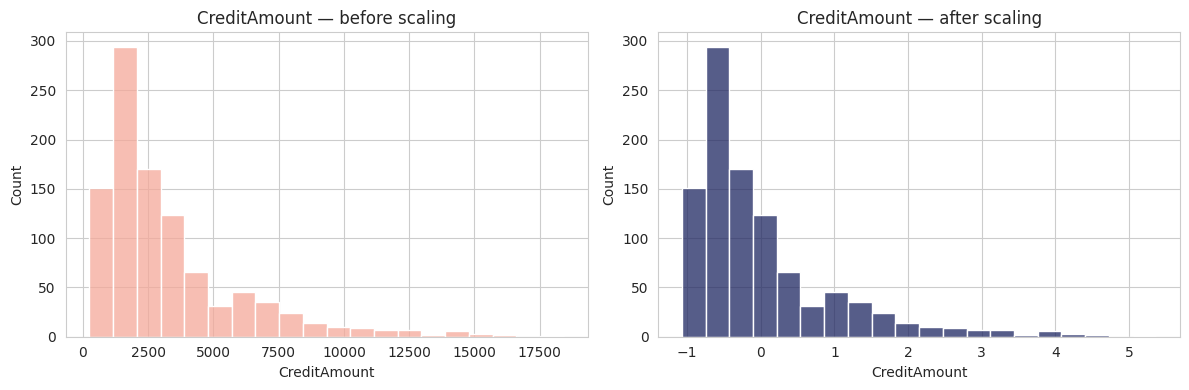

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0], color="#f5a99a")
axes[0].set_title("CreditAmount — before scaling")
sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1], color="#1E2761")
axes[1].set_title("CreditAmount — after scaling")
plt.tight_layout()
plt.show()


## Part D · Assessing candidate features

### Scoring the Candidate Inputs

In this section, we separate `Risk` from the other columns and use `SelectKBest` to score the features. The scores help us see which features may be useful for predicting risk. We keep all the features, so no columns are removed in this step.

In [ ]:
X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

selector = SelectKBest(score_func=f_classif, k="all")
selector.fit(X, y)

feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False).reset_index(drop=True)

feature_scores


,Feature,Score
0,CheckingAccount,111.721482
1,Duration,48.333790
2,SavingAccounts,33.948465
3,CreditAmount,24.482366
4,Age,8.356995
5,Sex,5.720350
6,Purpose,3.745234
7,Job,1.070584
8,Housing,0.372463


### Presenting the feature-score ranking



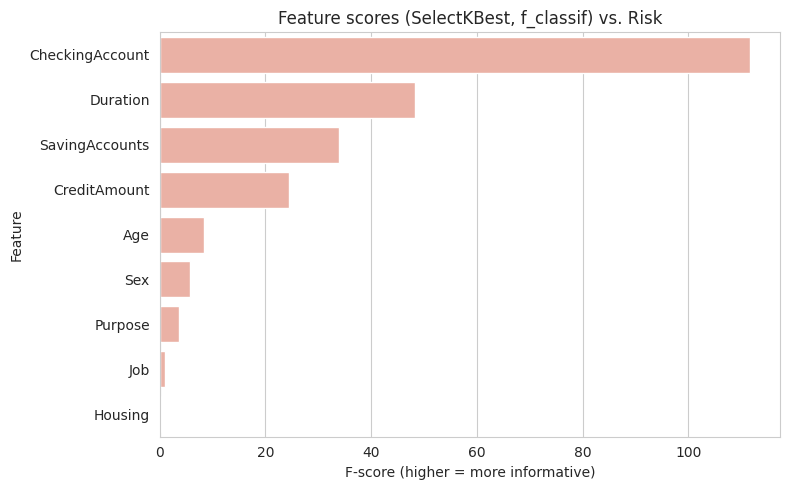

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(data=feature_scores, x="Score", y="Feature", color="#f5a99a")
plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")
plt.xlabel("F-score (higher = more informative)")
plt.tight_layout()
plt.show()
